# Monte Carlo option pricing

Pricing European options with the Black-Scholes formula and then by Monte Carlo simulation of the stock price, to see how the simulation converges and how to make it converge faster. Then using the same simulation for options that don't have a simple formula (Asian and barrier options), and estimating the Greeks.

In [1]:
# import packages

import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm

np.random.seed(42)

## The model

Under the risk-neutral measure the stock follows geometric Brownian motion:

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t$$

which has the exact solution

$$S_T = S_0 \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right), \qquad Z \sim N(0,1)$$

The price of an option is the discounted expected payoff, $V_0 = e^{-rT}\,\mathbb{E}[\text{payoff}]$.

I use Apple (AAPL) for a real starting price and volatility: the spot is the last close of 2024 and $\sigma$ is the annualised standard deviation of daily log returns over 2024.

In [2]:
# Download one year of Apple prices
data = yf.download('AAPL', start='2024-01-01', end='2025-01-01', auto_adjust=True, progress=False)['Close']['AAPL']

log_returns = np.log(data / data.shift(1)).dropna()

S0 = float(data.iloc[-1])
sigma = float(log_returns.std() * np.sqrt(252))  # annualised volatility

print('Spot price S0:', round(S0, 2))
print('Historical volatility:', round(sigma, 4))

Spot price S0: 248.62
Historical volatility: 0.2232


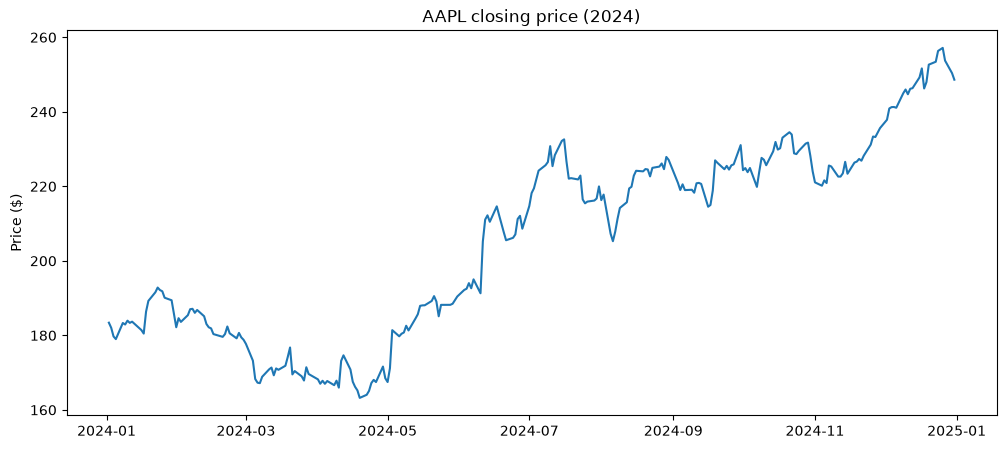

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data)
plt.title('AAPL closing price (2024)')
plt.ylabel('Price ($)')
plt.show()

In [4]:
# Option parameters
K = 250       # strike (close to the money)
T = 1.0       # one year to expiry
r = 0.04      # risk-free rate (assumed)

## 1. Black-Scholes closed form

$$C = S_0 N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0 N(-d_1)$$

$$d_1 = \frac{\ln(S_0/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

where $N$ is the standard normal CDF.

In [5]:
def d1_d2(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2

def bs_call(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_put(S, K, T, r, sigma):
    d1, d2 = d1_d2(S, K, T, r, sigma)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [6]:
call_bs = bs_call(S0, K, T, r, sigma)
put_bs = bs_put(S0, K, T, r, sigma)

print('Black-Scholes call:', round(call_bs, 4))
print('Black-Scholes put: ', round(put_bs, 4))

Black-Scholes call: 26.1877
Black-Scholes put:  17.7693


### Put-call parity

For European options on a non-dividend stock, holding a call and selling a put is the same as holding the stock and borrowing the discounted strike:

$$C - P = S_0 - K e^{-rT}$$

In [7]:
lhs = call_bs - put_bs
rhs = S0 - K * np.exp(-r * T)
print('C - P:          ', lhs)
print('S0 - K*exp(-rT):', rhs)
print('Difference:     ', abs(lhs - rhs))

# Check it across a range of strikes too
strikes = np.linspace(150, 350, 41)
parity_error = (bs_call(S0, strikes, T, r, sigma) - bs_put(S0, strikes, T, r, sigma)) - (S0 - strikes * np.exp(-r * T))
print('Max parity error over 41 strikes:', np.max(np.abs(parity_error)))

C - P:           8.418439162114524
S0 - K*exp(-rT): 8.41843916211451
Difference:      1.4210854715202004e-14
Max parity error over 41 strikes: 6.394884621840902e-14


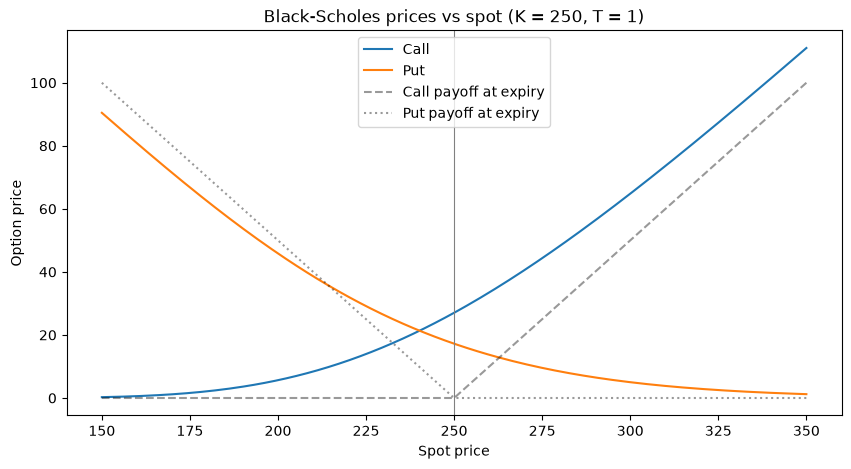

In [8]:
spots = np.linspace(150, 350, 200)

plt.figure(figsize=(10, 5))
plt.plot(spots, bs_call(spots, K, T, r, sigma), label='Call')
plt.plot(spots, bs_put(spots, K, T, r, sigma), label='Put')
plt.plot(spots, np.maximum(spots - K, 0), 'k--', alpha=0.4, label='Call payoff at expiry')
plt.plot(spots, np.maximum(K - spots, 0), 'k:', alpha=0.4, label='Put payoff at expiry')
plt.axvline(K, color='grey', linewidth=0.8)
plt.title('Black-Scholes prices vs spot (K = 250, T = 1)')
plt.xlabel('Spot price')
plt.ylabel('Option price')
plt.legend()
plt.show()

## 2. Simulating geometric Brownian motion

To simulate whole paths I split $[0, T]$ into $n$ steps of size $\Delta t = T/n$ and use the exact update

$$S_{t+\Delta t} = S_t \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z\right)$$

In [9]:
def simulate_gbm(S0, r, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    Z = np.random.standard_normal((n_paths, n_steps))
    increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
    log_paths = np.cumsum(increments, axis=1)
    log_paths = np.hstack([np.zeros((n_paths, 1)), log_paths])  # start every path at S0
    return S0 * np.exp(log_paths)

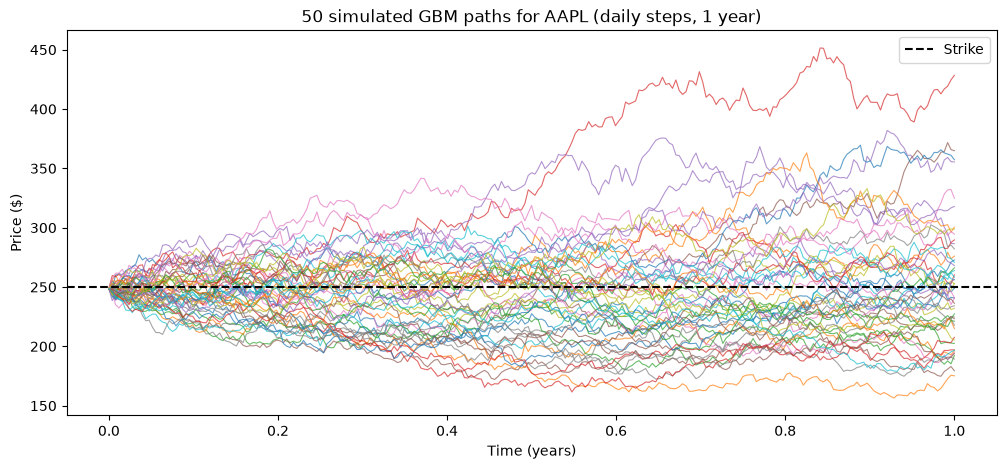

In [10]:
paths = simulate_gbm(S0, r, sigma, T, 252, 50)
t = np.linspace(0, T, 253)

plt.figure(figsize=(12, 5))
plt.plot(t, paths.T, linewidth=0.8, alpha=0.7)
plt.axhline(K, color='black', linestyle='--', label='Strike')
plt.title('50 simulated GBM paths for AAPL (daily steps, 1 year)')
plt.xlabel('Time (years)')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

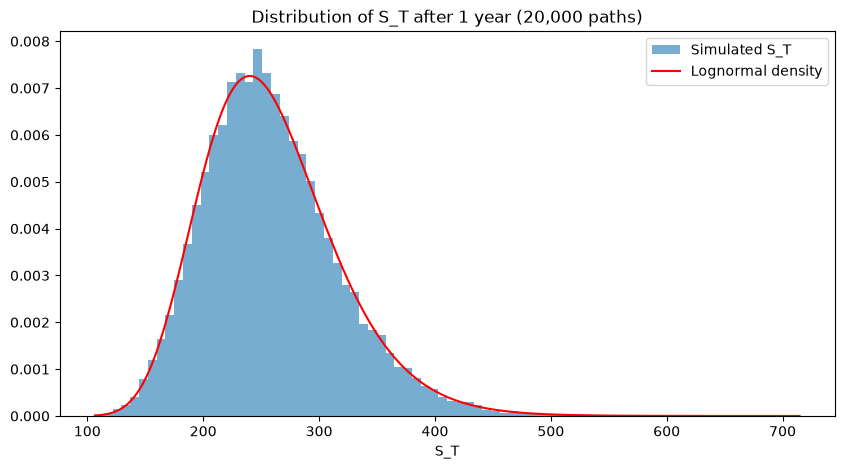

Mean of simulated S_T: 258.5
Theoretical mean S0*exp(rT): 258.76


In [11]:
# Check the terminal distribution against the lognormal density
paths = simulate_gbm(S0, r, sigma, T, 252, 20000)
ST = paths[:, -1]

x = np.linspace(ST.min(), ST.max(), 300)
mu_log = np.log(S0) + (r - 0.5 * sigma**2) * T
pdf = norm.pdf(np.log(x), mu_log, sigma * np.sqrt(T)) / x

plt.figure(figsize=(10, 5))
plt.hist(ST, bins=80, density=True, alpha=0.6, label='Simulated S_T')
plt.plot(x, pdf, 'r', label='Lognormal density')
plt.title('Distribution of S_T after 1 year (20,000 paths)')
plt.xlabel('S_T')
plt.legend()
plt.show()

print('Mean of simulated S_T:', round(ST.mean(), 2))
print('Theoretical mean S0*exp(rT):', round(S0 * np.exp(r * T), 2))

## 3. Monte Carlo pricing of the European options

A European payoff only depends on $S_T$, so I can sample $S_T$ directly without the intermediate steps. With $N$ samples of the discounted payoff $Y_i$:

$$\hat{V} = \frac{1}{N}\sum_{i=1}^N Y_i, \qquad \text{SE} = \frac{s_Y}{\sqrt{N}}, \qquad \text{95\% CI} = \hat{V} \pm 1.96\,\text{SE}$$

By the central limit theorem the error shrinks like $1/\sqrt{N}$, so 100 times more paths gives one more decimal place.

In [12]:
def mc_european(S0, K, T, r, sigma, n_paths, option='call'):
    Z = np.random.standard_normal(n_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    if option == 'call':
        payoff = np.maximum(ST - K, 0)
    else:
        payoff = np.maximum(K - ST, 0)
    Y = np.exp(-r * T) * payoff
    price = Y.mean()
    se = Y.std(ddof=1) / np.sqrt(n_paths)
    return price, se

In [13]:
call_mc, call_se = mc_european(S0, K, T, r, sigma, 100000, 'call')
put_mc, put_se = mc_european(S0, K, T, r, sigma, 100000, 'put')

print(f'Call  MC: {call_mc:.4f} +/- {1.96*call_se:.4f}   BS: {call_bs:.4f}')
print(f'Put   MC: {put_mc:.4f} +/- {1.96*put_se:.4f}   BS: {put_bs:.4f}')

Call  MC: 25.9604 +/- 0.2453   BS: 26.1877
Put   MC: 17.8281 +/- 0.1587   BS: 17.7693


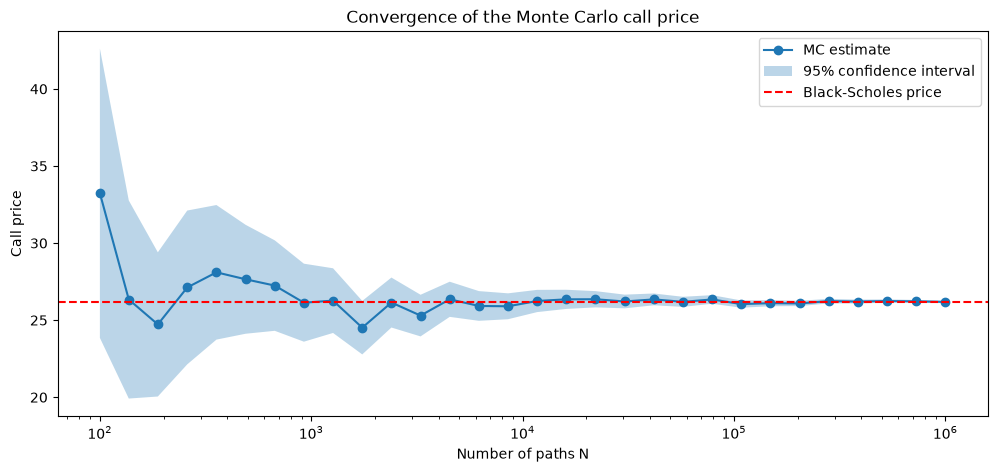

Number of estimates whose 95% CI contains the BS price: 30 out of 30


In [14]:
# Price the call with more and more paths
N_values = np.unique(np.logspace(2, 6, 30).astype(int))
estimates = []
errors = []

for N in N_values:
    price, se = mc_european(S0, K, T, r, sigma, N, 'call')
    estimates.append(price)
    errors.append(se)

estimates = np.array(estimates)
errors = np.array(errors)

plt.figure(figsize=(12, 5))
plt.plot(N_values, estimates, 'o-', label='MC estimate')
plt.fill_between(N_values, estimates - 1.96 * errors, estimates + 1.96 * errors, alpha=0.3, label='95% confidence interval')
plt.axhline(call_bs, color='red', linestyle='--', label='Black-Scholes price')
plt.xscale('log')
plt.title('Convergence of the Monte Carlo call price')
plt.xlabel('Number of paths N')
plt.ylabel('Call price')
plt.legend()
plt.show()

inside = np.abs(estimates - call_bs) <= 1.96 * errors
print('Number of estimates whose 95% CI contains the BS price:', inside.sum(), 'out of', len(N_values))

### Error rate on a log-log plot

One run at each $N$ is noisy, so I repeat the pricing 100 times at each $N$ and take the root mean squared error against the Black-Scholes price. If $\text{error} \approx c N^{-1/2}$ then $\log(\text{error}) = \log c - \tfrac{1}{2}\log N$, a straight line with slope $-0.5$.

In [15]:
N_grid = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
n_repeats = 100
rmse = []
mean_se = []

for N in N_grid:
    prices = []
    ses = []
    for i in range(n_repeats):
        price, se = mc_european(S0, K, T, r, sigma, N, 'call')
        prices.append(price)
        ses.append(se)
    rmse.append(np.sqrt(np.mean((np.array(prices) - call_bs)**2)))
    mean_se.append(np.mean(ses))

rmse = np.array(rmse)
mean_se = np.array(mean_se)

# Fit a straight line in log-log space
slope, intercept = np.polyfit(np.log(N_grid), np.log(rmse), 1)
print('Fitted slope of log(RMSE) vs log(N):', round(slope, 3))

Fitted slope of log(RMSE) vs log(N): -0.496


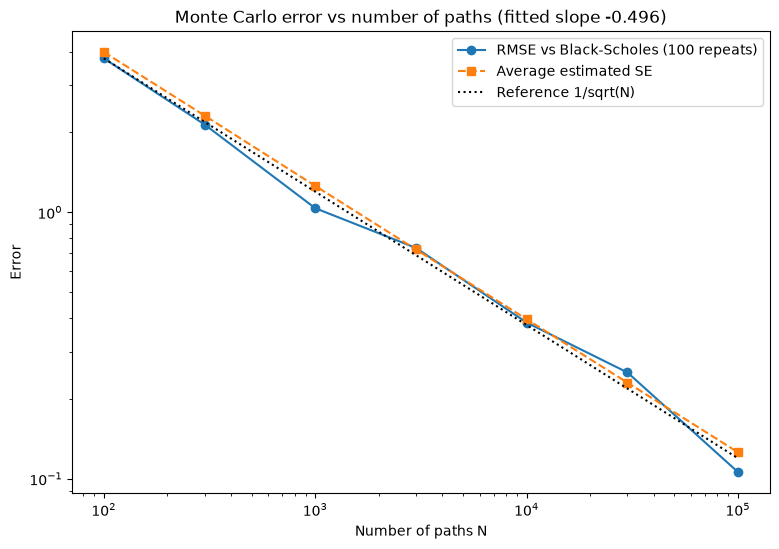

In [16]:
plt.figure(figsize=(9, 6))
plt.loglog(N_grid, rmse, 'o-', label='RMSE vs Black-Scholes (100 repeats)')
plt.loglog(N_grid, mean_se, 's--', label='Average estimated SE')
plt.loglog(N_grid, rmse[0] * np.sqrt(N_grid[0] / N_grid), 'k:', label='Reference 1/sqrt(N)')
plt.title(f'Monte Carlo error vs number of paths (fitted slope {slope:.3f})')
plt.xlabel('Number of paths N')
plt.ylabel('Error')
plt.legend()
plt.show()

## 4. Variance reduction

Since the error is $\sigma_Y/\sqrt{N}$, the other way to reduce it is to reduce $\sigma_Y$. I compare everything with the same budget of $N = 100{,}000$ simulated payoffs.

**Antithetic variates.** For every $Z$ also use $-Z$. The two payoffs are negatively correlated, so their average has lower variance:

$$\hat{V}_{AV} = \frac{1}{N/2}\sum_{i=1}^{N/2} \frac{Y(Z_i) + Y(-Z_i)}{2}$$

**Control variate.** Use a variable $X$ with a known mean that is correlated with the payoff. Here $X = e^{-rT}S_T$, whose mean is exactly $S_0$:

$$\hat{V}_{CV} = \frac{1}{N}\sum_{i=1}^N \left(Y_i - b\,(X_i - S_0)\right), \qquad b^* = \frac{\text{Cov}(Y, X)}{\text{Var}(X)}$$

The variance is reduced by a factor of $1 - \rho_{XY}^2$.

In [17]:
def mc_antithetic(S0, K, T, r, sigma, n_paths):
    Z = np.random.standard_normal(n_paths // 2)
    ST_plus = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    ST_minus = S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Z)
    Y = np.exp(-r * T) * 0.5 * (np.maximum(ST_plus - K, 0) + np.maximum(ST_minus - K, 0))
    return Y.mean(), Y.std(ddof=1) / np.sqrt(len(Y))

def mc_control_variate(S0, K, T, r, sigma, n_paths):
    Z = np.random.standard_normal(n_paths)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    Y = np.exp(-r * T) * np.maximum(ST - K, 0)
    X = np.exp(-r * T) * ST           # control, E[X] = S0
    b = np.cov(Y, X)[0, 1] / np.var(X, ddof=1)
    Y_cv = Y - b * (X - S0)
    return Y_cv.mean(), Y_cv.std(ddof=1) / np.sqrt(n_paths), np.corrcoef(Y, X)[0, 1]

In [18]:
N = 100000
plain_price, plain_se = mc_european(S0, K, T, r, sigma, N, 'call')
av_price, av_se = mc_antithetic(S0, K, T, r, sigma, N)
cv_price, cv_se, rho = mc_control_variate(S0, K, T, r, sigma, N)

print('Correlation between payoff and control:', round(rho, 4))
print()
print(f"{'Method':<20}{'Price':>10}{'SE':>10}{'Var reduction':>16}")
print(f"{'Black-Scholes':<20}{call_bs:>10.4f}")
for name, p, s in [('Plain MC', plain_price, plain_se), ('Antithetic', av_price, av_se), ('Control variate', cv_price, cv_se)]:
    print(f'{name:<20}{p:>10.4f}{s:>10.4f}{(plain_se / s)**2:>15.2f}x')

Correlation between payoff and control: 0.9155

Method                   Price        SE   Var reduction
Black-Scholes          26.1877
Plain MC               26.2381    0.1255           1.00x
Antithetic             26.1562    0.0946           1.76x
Control variate        26.1460    0.0505           6.18x


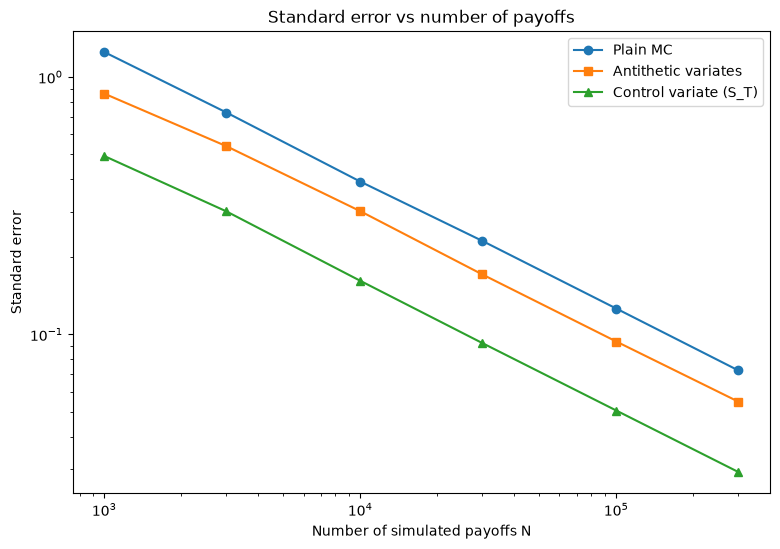

In [19]:
# Standard error of each method as N grows
N_grid = np.array([1000, 3000, 10000, 30000, 100000, 300000])
se_plain, se_av, se_cv = [], [], []
for N in N_grid:
    se_plain.append(mc_european(S0, K, T, r, sigma, N, 'call')[1])
    se_av.append(mc_antithetic(S0, K, T, r, sigma, N)[1])
    se_cv.append(mc_control_variate(S0, K, T, r, sigma, N)[1])

plt.figure(figsize=(9, 6))
plt.loglog(N_grid, se_plain, 'o-', label='Plain MC')
plt.loglog(N_grid, se_av, 's-', label='Antithetic variates')
plt.loglog(N_grid, se_cv, '^-', label='Control variate (S_T)')
plt.title('Standard error vs number of payoffs')
plt.xlabel('Number of simulated payoffs N')
plt.ylabel('Standard error')
plt.legend()
plt.show()